# DM ZG504 · Lab 1 — From raw shop-floor data to a trusted table
**Covers:** Python and pandas basics · data quality checks · cleaning (the *Transform* of ETL) · SQL with JOINs and GROUP BY · a small ETL pipeline · exploratory data analysis (EDA)

**Time:** about 2 hours. **How to work:** run the cells from top to bottom. Most code is already written. You complete the cells marked **`# TODO`** (usually one to three lines) and answer the questions marked ✍️ in the text cell under them. After most TODO cells there is a ✅/❌ check that tells you whether your result is right.

**The plant.** A small machining plant has two lines. Line L1 has machines M01 (press) and M02 (welder); line L2 has M03 (press), M04 (welder) and M05, a new press that is still being commissioned and has not produced anything yet. The plant works three shifts: A 06:00–14:00, B 14:00–22:00, C 22:00–06:00 (Indian Standard Time). You receive the exports for **2 and 3 November 2026** (two production days, from 06:00 on 2 Nov to 06:00 on 4 Nov):

| File | One row is … | Columns |
|---|---|---|
| `machines.csv` | one machine (master data) | machine_id, line_id, machine_type, ideal_ct_s (ideal cycle time, seconds), status |
| `production_events.csv` | one finished part | event_id, machine_id, ts (time stamp), cycle_s (cycle time, s), result (OK / NOK), run_id, ingested_at |
| `downtime_log.csv` | one stoppage | machine_id, start_ts, end_ts, reason |
| `m03_spindle_temp.csv` | one temperature reading of M03's spindle per minute | ts, temp_C |

**The business question you will answer at the end:** *the quality engineer says M03 made far more scrap on the second day. Is that true, and what does the data suggest as the cause?*

In [27]:
# @title ▶ Setup — run this cell first (it creates the data files; you do not need to read it) { display-mode: "form" }
# Generates the raw shop-floor files for Lab 1 into ./data (fixed seed: everyone gets the same data)
import os
import numpy as np
import pandas as pd

rng = np.random.default_rng(504)
os.makedirs("data", exist_ok=True)
IST = "Asia/Kolkata"
start = pd.Timestamp("2026-11-02 06:00", tz=IST)
end = start + pd.Timedelta(days=2)

machines = pd.DataFrame({
    "machine_id": ["M01", "M02", "M03", "M04", "M05"],
    "line_id": ["L1", "L1", "L2", "L2", "L2"],
    "machine_type": ["Press", "Weld", "Press", "Weld", "Press"],
    "ideal_ct_s": [40, 50, 45, 60, 45],
    "status": ["active", "active", "active", "active", "commissioning"],
})

# ---- spindle temperature of M03, one reading per minute (true process value) ----
minutes = pd.date_range(start, end, freq="min", inclusive="left")
h = (minutes - start).total_seconds().to_numpy() / 3600
temp_true = 60 + rng.normal(0, 0.6, len(h))
day2 = h >= 24
temp_true[day2] += (h[day2] - 24) / 24 * 10          # coolant problem: +10 °C over day 2
temp_true += 1.5 * np.sin(2 * np.pi * h / 24)        # day/night ambient effect

# ---- downtime events ----
reasons = ["Breakdown", "Changeover", "Minor stop", "Material wait"]
dur_rng = {"Breakdown": (30, 90), "Changeover": (20, 40), "Minor stop": (3, 10), "Material wait": (10, 30)}
n_stops = {"M01": 8, "M02": 12, "M03": 9, "M04": 7}
down = []
for m, k in n_stops.items():
    for _ in range(k):
        r = rng.choice(reasons, p=[0.25, 0.15, 0.4, 0.2])
        s = start + pd.Timedelta(minutes=int(rng.integers(0, 2 * 24 * 60 - 120)))
        d = int(rng.integers(*dur_rng[r]))
        down.append((m, s, s + pd.Timedelta(minutes=d), r))
down = pd.DataFrame(down, columns=["machine_id", "start_ts", "end_ts", "reason"]).sort_values(["machine_id", "start_ts"])

# ---- production events (one row per part) ----
rows = []
for _, mc in machines[machines.status == "active"].iterrows():
    m, ict = mc.machine_id, mc.ideal_ct_s
    st = down[down.machine_id == m]
    s0 = ((st.start_ts - start).dt.total_seconds()).to_numpy()
    s1 = ((st.end_ts - start).dt.total_seconds()).to_numpy()
    t = 0.0
    while t < 48 * 3600:
        inside = (s0 <= t) & (s1 > t)
        if inside.any():
            t = s1[inside].max()
            continue
        ct = ict * rng.lognormal(np.log(1.08), 0.07)
        t += ct
        if t >= 48 * 3600:
            break
        p = 0.02
        if m == "M03":
            p = 0.01 + 0.012 * max(0.0, temp_true[int(t // 60)] - 61)
        rows.append((m, start + pd.Timedelta(seconds=round(t, 3)), round(ct, 1), "NOK" if rng.random() < p else "OK"))
ev = pd.DataFrame(rows, columns=["machine_id", "ts", "cycle_s", "result"]).sort_values("ts").reset_index(drop=True)
ev.insert(0, "event_id", np.arange(100001, 100001 + len(ev)))

# ---- make it messy, the way real exports are ----
def ts_text(r):
    if r.machine_id == "M03":                       # M03 logger writes plant time with offset
        return r.ts.tz_convert(IST).strftime("%Y-%m-%dT%H:%M:%S+05:30")
    return r.ts.tz_convert("UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
ev["ts"] = ev.apply(ts_text, axis=1)
v = rng.random(len(ev))
ev.loc[(ev.machine_id == "M02") & (v < 0.015), "cycle_s"] = 0.0      # M02 counter glitch: zero cycle times
big = v > 0.997
ev.loc[big, "cycle_s"] = rng.integers(1800, 5000, big.sum()).astype(float)   # part booked after a long idle
variants = lambda m: [m, m.lower(), m[0] + "-" + m[1:], " " + m + " "]
ev["machine_id"] = [rng.choice(variants(m)) if rng.random() < 0.1 else m for m in ev.machine_id]
ct = ev["cycle_s"].astype(str)
u = rng.random(len(ev))
ct[u < 0.008] = ""
ct[(u >= 0.008) & (u < 0.012)] = "-999"
ct[(u >= 0.012) & (u < 0.014)] = "err"
ev["cycle_s"] = ct
ev["result"] = [rng.choice(["ok", "Ok"]) if (r == "OK" and rng.random() < 0.05) else r for r in ev.result]
ev["run_id"] = "r1"
ev["ingested_at"] = "2026-11-04 07:00:00"

# overlap re-load: the 21:00–22:00 IST hour of day 1 was loaded again by the next run
t_local = pd.to_datetime(ev.ts, utc=True, format="ISO8601").dt.tz_convert(IST)
ov = ev[(t_local >= pd.Timestamp("2026-11-02 21:00", tz=IST)) & (t_local < pd.Timestamp("2026-11-02 22:00", tz=IST))].copy()
ov["run_id"] = "r2"
ov["ingested_at"] = "2026-11-04 08:00:00"
ev = pd.concat([ev, ov]).sort_values(["event_id", "run_id"]).reset_index(drop=True)

# ---- sensor file with sensor errors and gaps ----
sens = pd.DataFrame({"ts": minutes.tz_convert("UTC").strftime("%Y-%m-%dT%H:%M:%SZ"), "temp_C": temp_true.round(2)})
idx = rng.choice(len(sens), 18, replace=False)
sens.loc[idx[:15], "temp_C"] = -40.0                  # disconnected thermocouple
sens.loc[idx[15:], "temp_C"] = 999.9                  # overflow code
sens.loc[rng.choice(len(sens), 25, replace=False), "temp_C"] = np.nan
gap = (minutes >= pd.Timestamp("2026-11-03 02:10", tz=IST)) & (minutes < pd.Timestamp("2026-11-03 02:55", tz=IST))
sens = sens[~gap]

down_out = down.copy()
for c in ["start_ts", "end_ts"]:
    down_out[c] = down_out[c].dt.strftime("%Y-%m-%dT%H:%M:%S+05:30")

machines.to_csv("data/machines.csv", index=False)
ev.to_csv("data/production_events.csv", index=False)
down_out.to_csv("data/downtime_log.csv", index=False)
sens.to_csv("data/m03_spindle_temp.csv", index=False)
print("Lab 1 data written to ./data:", {f: len(pd.read_csv("data/" + f)) for f in sorted(os.listdir("data"))})

import sqlite3
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

def check(ok, good, bad):
    print(("✅ " + good) if ok else ("❌ " + bad))

Lab 1 data written to ./data: {'downtime_log.csv': 36, 'm03_spindle_temp.csv': 2835, 'machines.csv': 5, 'production_events.csv': 12866}


## Part A — First look at the raw data (≈ 10 min)
We read every column **as text** (`dtype=str`). That way pandas does not guess types for us; we decide every conversion ourselves and can see what goes wrong. This is the *Extract* step: take the data exactly as the source gives it.

In [28]:
raw = pd.read_csv("data/production_events.csv", dtype=str)
machines = pd.read_csv("data/machines.csv")
downtime_raw = pd.read_csv("data/downtime_log.csv", dtype=str)
temp_raw = pd.read_csv("data/m03_spindle_temp.csv")
raw.head()

,event_id,machine_id,ts,cycle_s,result,run_id,ingested_at
0,100001,M02,2026-11-02T00:30:46Z,46.5,NOK,r1,2026-11-04 07:00:00
1,100002,M01,2026-11-02T00:30:48Z,48.7,OK,r1,2026-11-04 07:00:00
2,100003,M03,2026-11-02T06:00:50+05:30,50.1,OK,r1,2026-11-04 07:00:00
3,100004,M04,2026-11-02T00:31:05Z,65.8,OK,r1,2026-11-04 07:00:00
4,100005,M01,2026-11-02T00:31:32Z,43.9,OK,r1,2026-11-04 07:00:00


In [29]:
# TODO A1: print (1) the number of rows and columns of raw, (2) the data type of every column,
#          (3) the different spellings found in the machine_id column, (4) the different values in result.
# Hint: .shape, .dtypes, .unique()

# (1) Number of rows and columns
print("Shape of raw:", raw.shape)

# (2) Data type of every column
print("\nData types:")
print(raw.dtypes)

# (3) Different spellings/values in machine_id
print("\nUnique machine_id values:")
print(raw["machine_id"].unique())

# (4) Different values in result
print("\nUnique result values:")
print(raw["result"].unique())


Shape of raw: (12866, 7)

Data types:
event_id       str
machine_id     str
ts             str
cycle_s        str
result         str
run_id         str
ingested_at    str
dtype: object

Unique machine_id values:
<StringArray>
['M02', 'M01', 'M03', 'M04', ' M01 ', ' M04 ', 'M-03', ' M02 ', 'M-02', ' M03 ', 'm03', 'm04', 'M-04', 'm02', 'm01', 'M-01']
Length: 16, dtype: str

Unique result values:
<StringArray>
['NOK', 'OK', 'ok', 'Ok']
Length: 4, dtype: str


✍️ **Q A1.** Name at least four problems you can already see in the raw production data (look at machine_id, ts, cycle_s, result and the last two columns). For each, say what would go wrong in a report if it were not fixed.

*Your answer:* 
1)Inconsistent machine_id values

The machine_id column contains multiple spellings of the same machine, such as M01, M-01, M01, m01, M02, M-02, m02, etc.
If not cleaned, reports would treat these as different machines, causing incorrect machine-level production counts, downtime calculations, and performance comparisons.

2)Inconsistent timestamp (ts) formats

The ts column uses different timestamp formats and time zone representations (e.g., 2026-11-02T00:30:46Z, 2026-11-02T06:00:50+05:30, 2026-11-02T00:31:32Z).
If not standardized, events may be assigned to the wrong hour, shift, or day, leading to inaccurate trend analyses and production summaries.

3)cycle_s stored as text instead of numeric

All columns were loaded as strings (object type), including cycle_s.
If not converted to a numeric type, calculations such as average cycle time, minimum/maximum cycle time, and performance metrics could fail or produce incorrect results.

4)Inconsistent result values

The result column contains different spellings/cases of the same outcome: OK, ok, Ok, NOK.
If not standardized, defect and yield reports would count OK, ok, and Ok as separate categories, producing incorrect quality statistics.

5)run_id may not uniquely identify a production run

From the sample data, all records appear to have the same value (r1).
If run_id is expected to identify different runs, analyses by production run could be misleading or impossible.

6)ingested_at differs from event time

The ingested_at column shows a processing timestamp (2026-11-04 07:00:00) that is later than the actual event timestamp in ts.
If a report mistakenly uses ingested_at instead of ts, production activity would be reported on the wrong date and time.

## Part B — Cleaning: the *Transform* step (≈ 35 min)
We build a clean table `ev` column by column. Each step fixes one problem from Q A1. Keep the raw table unchanged — we always want to be able to go back to the source.

In [30]:
ev = raw.copy()

**B1. One spelling per machine.** Remove spaces at both ends, change to upper case and delete the hyphen, so that `' m-01 '` becomes `'M01'`.

In [31]:
# TODO B1: clean ev["machine_id"] in one line using .str.strip(), .str.upper() and .str.replace("-", "")
ev["machine_id"] = ev["machine_id"].str.strip().str.upper().str.replace("-", "", regex=False)

check(set(ev["machine_id"]) == {"M01", "M02", "M03", "M04"},
      "machine_id now has exactly four values", "still more than four spellings: " + str(sorted(set(map(str, ev["machine_id"])))))

✅ machine_id now has exactly four values


**B2. One clock.** Convert the text time stamps to real date-times. `utc=True` puts every value on the UTC clock (a `+05:30` value is converted correctly), `format="ISO8601"` tells pandas the text follows the international standard. Then add a second column in plant time (`Asia/Kolkata`) because shifts are defined in plant time.

In [32]:
# TODO B2: create ev["ts"] (UTC) with pd.to_datetime(..., utc=True, format="ISO8601")
#          and ev["ts_local"] with .dt.tz_convert("Asia/Kolkata")
ev["ts"] = pd.to_datetime(ev["ts"], utc=True, format="ISO8601")
ev["ts_local"] = ev["ts"].dt.tz_convert("Asia/Kolkata")

check(str(ev["ts_local"].dtype) == "datetime64[us, Asia/Kolkata]" or "Asia/Kolkata" in str(ev["ts_local"].dtype),
      "time stamps converted; first part at " + str(ev["ts_local"].min()), "ts_local is not a plant-time date-time column yet")

✅ time stamps converted; first part at 2026-11-02 06:00:46+05:30


✍️ **Q B2.** M03's logger writes plant time (`+05:30`), the others write UTC (`Z`). Suppose someone simply deleted the `+05:30` and treated all values as UTC. What would happen to M03's parts in an hourly or shift report?

*Your answer:* If the +05:30 offset were removed and M03 timestamps were incorrectly treated as UTC, all M03 events would appear 5 hours 30 minutes later than they actually occurred.

For example:

Actual M03 timestamp: 2026-11-02T06:00:50+05:30
Correct UTC time: 2026-11-02T00:30:50Z
Incorrectly treated as UTC: 2026-11-02T06:00:50Z

As a result, M03 parts would be assigned to the wrong hour and possibly the wrong shift. Production that really happened during an early-morning shift could be reported in a later shift, causing:

Incorrect hourly production counts
Wrong shift-level KPIs
Misleading machine utilization and throughput metrics
Difficulty comparing M03 with the other machines

In short, M03's production would be shifted forward by 5.5 hours, making time-based reports inaccurate.

**B3. Numbers that arrive as text.** `pd.to_numeric(..., errors="coerce")` converts every value it can and turns the rest (blanks, `err`) into `NaN` (missing). The value `-999` is a **sentinel**: the machine's code for "no measurement". It *is* a number, so it survives the conversion — we must replace it with `NaN` ourselves. Order matters: convert first, then replace the number −999.

In [33]:
# TODO B3: convert ev["cycle_s"] to numbers (errors="coerce"), then replace -999 by np.nan
ev["cycle_s"] = pd.to_numeric(ev["cycle_s"], errors="coerce")
ev["cycle_s"] = ev["cycle_s"].replace(-999, np.nan)

n_missing = ev["cycle_s"].isna().sum()
check(n_missing > 0 and (ev["cycle_s"] < 0).sum() == 0,
      f"cycle_s is numeric; {n_missing} values are missing (blanks, 'err' and -999)", "check the conversion and the -999 replacement")

✅ cycle_s is numeric; 148 values are missing (blanks, 'err' and -999)


Note what we did **not** do: we did not delete the parts whose cycle time is missing. The part was still made — only its measurement failed. If we used `ev.dropna()` we would lose those parts from every count, and the output and quality figures would be wrong.

**B4. Good or bad part.** Create a True/False column `is_good`.

In [34]:
# TODO B4: ev["is_good"] should be True when result is "OK" in any spelling (OK, ok, Ok)
# Hint: ev["result"].str.upper() == "OK"
ev["is_good"] = ev["result"].str.upper() == "OK"

check(int((~ev["is_good"]).sum()) == int((raw["result"] == "NOK").sum()),
      f"{int((~ev['is_good']).sum())} NOK rows, {int(ev['is_good'].sum())} OK rows", "the number of NOK rows does not match the raw data")

✅ 279 NOK rows, 12587 OK rows


**B5. Duplicates.** Some rows were loaded twice: once by run `r1` and again by run `r2`. First see what `drop_duplicates()` without arguments does, then deduplicate on the **business key** `event_id` (one event = one part), keeping the latest load.

In [35]:
print("rows before:", len(ev))
print("rows after drop_duplicates() with no arguments:", len(ev.drop_duplicates()))
print("event_ids that appear more than once:", ev["event_id"].duplicated().sum())

rows before: 12866
rows after drop_duplicates() with no arguments: 12866
event_ids that appear more than once: 275


In [36]:
# TODO B5: sort ev by "ingested_at", then drop duplicates using subset=["event_id"] and keep="last"
ev = ev.sort_values("ingested_at").drop_duplicates(subset=["event_id"], keep="last")

check(ev["event_id"].is_unique and len(ev) == raw["event_id"].nunique(),
      f"{len(ev)} unique parts remain", "event_id is still not unique")

✅ 12591 unique parts remain


✍️ **Q B5.** Why did `drop_duplicates()` with no arguments remove nothing? What would have happened to the parts produced between 21:00 and 22:00 on 2 November if we had stopped there?

*Your answer:* drop_duplicates() with no arguments removes only rows that are completely identical across all columns. In this dataset, the duplicated parts had the same event_id but differed in at least one other field (for example, a later ingested_at timestamp or a corrected value), so no rows were considered exact duplicates and nothing was removed.

If we had stopped there, the 275 duplicated event records would have remained in the data and those parts would have been counted twice. As a result, the production report for 21:00-22:00 on 2 November would have shown artificially high output, inflated machine counts, and potentially incorrect quality metrics because the same physical parts would be reported more than once. Using event_id as the unique key and keeping only the latest ingested record ensures that each produced part is counted exactly once.

**B6. Add master data and check validity.** Join each part to its machine's master data (line, ideal cycle time). `validate="many_to_one"` makes pandas stop with an error if the machine table had a repeated machine_id — otherwise every part of that machine would be duplicated silently. Then we compute a small **data-quality scorecard**.

In [37]:
# TODO B6: left-merge ev with machines on "machine_id", with validate="many_to_one"
n_before = len(ev)


ev = ev.merge(
    machines,
    on="machine_id",
    how="left",
    validate="many_to_one"
)

check(len(ev) == n_before and "ideal_ct_s" in ev.columns, "merge kept the row count and added the master data", "row count changed or columns missing")

✅ merge kept the row count and added the master data


In [38]:
# Data-quality scorecard (given). A cycle time is called "valid" if it lies between 0.5× and 3× the ideal cycle time.
valid_ct = ev["cycle_s"].between(0.5 * ev["ideal_ct_s"], 3 * ev["ideal_ct_s"])
scorecard = pd.DataFrame({
    "completeness of cycle_s (%)": ev.groupby("machine_id")["cycle_s"].apply(lambda s: 100 * s.notna().mean()),
    "validity of cycle_s (%)": valid_ct.groupby(ev["machine_id"]).mean() * 100,
    "parts": ev.groupby("machine_id").size(),
}).round(2)
scorecard

,completeness of cycle_s (%),validity of cycle_s (%),parts
machine_id,,,
M01,98.73,98.30,3715
M02,98.96,97.26,3069
M03,98.77,98.47,3333
M04,98.91,98.63,2474


✍️ **Q B6.** Compare completeness and validity for each machine. Which machine has a validity problem beyond missing values, what kind of values cause it (look at `ev.loc[~valid_ct & ev['cycle_s'].notna(), ['machine_id','cycle_s']]`), and should those parts be deleted from the part count?

*Your answer:* The scorecard shows that all machines have high completeness (about 98.7-99.0%), meaning only a small percentage of cycle-time values are missing. However, M02 has the lowest validity (97.26%), noticeably lower than the other machines (around 98.3-98.6%).

**B7. Shift and production date (given).** A part made at 02:00 on 3 November belongs to **shift C of 2 November** — the production day starts at 06:00. Shifting the time back by six hours before taking the date handles this.

In [39]:
def add_shift(df, col="ts_local"):
    h = df[col].dt.hour
    df["shift"] = np.select([(h >= 6) & (h < 14), (h >= 14) & (h < 22)], ["A", "B"], default="C")
    df["shift_date"] = (df[col] - pd.Timedelta(hours=6)).dt.strftime("%Y-%m-%d")
    return df

ev = add_shift(ev)
ev[["event_id", "machine_id", "ts_local", "shift_date", "shift", "cycle_s", "is_good"]].head()

,event_id,machine_id,ts_local,shift_date,shift,cycle_s,is_good
0,100001,M02,2026-11-02 06:00:46+05:30,2026-11-02,A,46.5,False
1,108297,M04,2026-11-03 13:23:15+05:30,2026-11-03,A,56.3,True
2,108298,M01,2026-11-03 13:23:47+05:30,2026-11-03,A,40.3,True
3,108299,M02,2026-11-03 13:24:04+05:30,2026-11-03,A,50.6,True
4,108300,M04,2026-11-03 13:24:23+05:30,2026-11-03,A,68.4,True


## Part C — SQL on the clean data (≈ 25 min)
We now *Load* the clean tables into a small SQLite database (a database in one file) and query them with SQL, as you would in a plant's MES or historian database. `run(sql)` sends a query and shows the result as a table.

In [45]:
con = sqlite3.connect("plant.db")
prod_sql = ev[["event_id", "machine_id", "shift_date", "shift", "cycle_s", "is_good"]].copy()
prod_sql["ts_local"] = ev["ts_local"].dt.strftime("%Y-%m-%d %H:%M:%S")
prod_sql["is_good"] = prod_sql["is_good"].astype(int)          # 1 = good, 0 = scrap
prod_sql.to_sql("production", con, if_exists="replace", index=False)
machines.to_sql("machine", con, if_exists="replace", index=False)
dt = downtime_raw.copy()
for c in ["start_ts", "end_ts"]:
    dt[c] = pd.to_datetime(dt[c], format="ISO8601").dt.strftime("%Y-%m-%d %H:%M:%S")
dt["minutes"] = (pd.to_datetime(dt["end_ts"]) - pd.to_datetime(dt["start_ts"])).dt.total_seconds() / 60
dt.to_sql("downtime", con, if_exists="replace", index=False)

def run(sql):
    return pd.read_sql_query(sql, con)

# Example (given): parts and good parts per machine
run('''
SELECT machine_id, COUNT(*) AS parts, SUM(is_good) AS good
FROM production
GROUP BY machine_id
ORDER BY machine_id
''')

,machine_id,parts,good
0,M01,3715,3662
1,M02,3069,3011
2,M03,3333,3216
3,M04,2474,2425


**C1. Scrap rate per line.** A rate for a group must be **total scrap ÷ total parts** (a ratio of sums), not the average of many small rates. Also remember that in SQL an integer divided by an integer gives an integer (3 / 200 = 0), so multiply by `1.0` first.

In [46]:
# TODO C1: replace the three ____ so that the query gives the scrap rate (%) per line
run('''
SELECT m.line_id,
       COUNT(*) AS parts,
       SUM(1 - p.is_good) AS scrap,
       100.0 * SUM(1 - p.is_good) / COUNT(*) AS scrap_pct
FROM production p
JOIN machine m ON m.machine_id = p.machine_id
GROUP BY m.line_id
''')

,line_id,parts,scrap,scrap_pct
0,L1,6784,111,1.636203
1,L2,5807,166,2.858619


**C2. Show every machine, including the one that produced nothing.** A `LEFT JOIN` keeps every row of the left table (machines) even when there is no matching production. Count a column of the *right* table (`p.event_id`): `COUNT(*)` would count the empty row of M05 as 1.

In [47]:
# TODO C2: complete the query so that all five machines appear and M05 shows 0 parts
run('''
SELECT m.machine_id, m.status, COUNT(p.event_id) AS parts
FROM machine m
LEFT JOIN production p ON p.machine_id = m.machine_id
GROUP BY m.machine_id, m.status
ORDER BY m.machine_id
''')

,machine_id,status,parts
0,M01,active,3715
1,M02,active,3069
2,M03,active,3333
3,M04,active,2474
4,M05,commissioning,0


**C3. Output per shift.** One row per machine, production date and shift.

In [48]:
# TODO C3: write the GROUP BY so that there is one row per machine, shift_date and shift
run('''
SELECT machine_id, shift_date, shift, COUNT(*) AS parts, SUM(is_good) AS good
FROM production
GROUP BY machine_id, shift_date, shift
ORDER BY machine_id, shift_date, shift
''').head(12)

,machine_id,shift_date,shift,parts,good
0,M01,2026-11-02,A,612,603
1,M01,2026-11-02,B,652,640
2,M01,2026-11-02,C,649,643
3,M01,2026-11-03,A,666,658
4,M01,2026-11-03,B,470,465
5,M01,2026-11-03,C,666,653
6,M02,2026-11-02,A,508,500
7,M02,2026-11-02,B,529,515
8,M02,2026-11-02,C,506,500
9,M02,2026-11-03,A,531,515


**C4. Debug a query.** A colleague wanted parts *and* downtime minutes per machine in one table and wrote the query below. Compare its numbers with the example query at the start of Part C.

In [49]:
faulty = run('''
SELECT p.machine_id, COUNT(*) AS parts, SUM(d.minutes) AS downtime_min
FROM production p
JOIN downtime d ON d.machine_id = p.machine_id
GROUP BY p.machine_id
''')
faulty

,machine_id,parts,downtime_min
0,M01,29720,746715.0
1,M02,36828,377487.0
2,M03,29997,583275.0
3,M04,17318,507170.0


✍️ **Q C4.** Why are both columns far too large? (Hint: how many rows does the JOIN create for one machine that has 3,700 parts and 8 downtime records?)

*Your answer:* The query performs a direct join between the production table and the downtime table using only machine_id:This creates a many-to-many join. Every production record for a machine is matched with every downtime record for that same machine.

For example, M01 has about 3,715 parts and 8 downtime records. The join creates:

3715×8=29,7203715 \times 8 = 29,7203715×8=29,720

rows, which matches the inflated parts value shown in the result.

Because each downtime event is repeated once for every part, the downtime minutes are also counted many times. Instead of summing each stop once, the query sums the same downtime record thousands of times.

As a result:

COUNT(*) is much larger than the real number of parts.
SUM(d.minutes) is much larger than the real downtime.
Both metrics are inflated because the join multiplies rows before aggregation.

The correct approach is to aggregate production and downtime separately (one row per machine in each table) and then join the aggregated results, or use subqueries/CTEs before joining.

In [51]:
# TODO C4: complete the corrected query: aggregate each table to one row per machine FIRST, then join
run('''
WITH p AS (
    SELECT machine_id, COUNT(*) AS parts
    FROM production
    GROUP BY machine_id
),
d AS (
    SELECT machine_id, SUM(minutes) AS downtime_min
    FROM downtime
    GROUP BY machine_id
)
SELECT m.machine_id,
       COALESCE(p.parts, 0) AS parts,
       COALESCE(d.downtime_min, 0) AS downtime_min
FROM machine m
LEFT JOIN p ON p.machine_id = m.machine_id
LEFT JOIN d ON d.machine_id = m.machine_id
ORDER BY m.machine_id
''')

,machine_id,parts,downtime_min
0,M01,3715,201.0
1,M02,3069,123.0
2,M03,3333,175.0
3,M04,2474,205.0
4,M05,0,0.0


## Part D — Put it together as a small ETL pipeline (≈ 15 min)
In a plant the cleaning must run automatically every night, not by hand in a notebook. A pipeline is simply the steps of Parts A–C written as functions: **extract → transform → validate → load**. The `transform` function below repeats your Part B steps. Your task is the **validate** step: rules that stop the pipeline *before* bad data reaches the database.

In [52]:
def extract(path="data/production_events.csv"):
    return pd.read_csv(path, dtype=str)

def transform(raw, machines):
    df = raw.copy()
    df["machine_id"] = df["machine_id"].str.strip().str.upper().str.replace("-", "")
    df["ts"] = pd.to_datetime(df["ts"], utc=True, format="ISO8601")
    df["ts_local"] = df["ts"].dt.tz_convert("Asia/Kolkata")
    df["cycle_s"] = pd.to_numeric(df["cycle_s"], errors="coerce").replace(-999, np.nan)
    df["is_good"] = df["result"].str.upper() == "OK"
    df = df.sort_values("ingested_at").drop_duplicates(subset=["event_id"], keep="last")
    df = df.merge(machines, on="machine_id", how="left", validate="many_to_one")
    return add_shift(df)

In [53]:
# TODO D1: write three checks with assert. The pipeline must stop if
#   (a) event_id is not unique,
#   (b) a machine_id is not in the machine master table,
#   (c) any time stamp is missing (NaT).
def validate(df, machines):
    assert df["event_id"].is_unique, "duplicate event_id"
    assert df["machine_id"].isin(machines["machine_id"]).all(), "unknown machine_id"
    assert df["ts"].notna().all(), "missing time stamp"
    return df

In [54]:
def load(df, con):
    out = df[["event_id", "machine_id", "shift_date", "shift", "cycle_s", "is_good"]].copy()
    out["is_good"] = out["is_good"].astype(int)
    out.to_sql("production", con, if_exists="replace", index=False)   # replace = safe to re-run
    return len(out)

def run_pipeline():
    return load(validate(transform(extract(), machines), machines), con)

print("run 1 loaded", run_pipeline(), "rows")
print("run 2 loaded", run_pipeline(), "rows  (same number: re-running does not double-count)")

# Does the validate step really catch problems? Feed it a table with an unknown machine:
bad = transform(extract(), machines)
bad.loc[bad.index[0], "machine_id"] = "M99"
try:
    validate(bad, machines)
except AssertionError as e:
    print("validate stopped the pipeline:", e)

run 1 loaded 12591 rows
run 2 loaded 12591 rows  (same number: re-running does not double-count)
validate stopped the pipeline: unknown machine_id


✍️ **Q D1.** Is this pipeline ETL or ELT? Explain using where the transformation happens and whether the raw data is kept. Why is it important that running the pipeline twice gives the same table (the pipeline is *idempotent*)?

*Your answer:* This pipeline is an ETL (Extract, Transform, Load) pipeline because the data is transformed before it is loaded into the database.

Extract: Read the raw CSV file (extract()).
Transform: Clean and standardize the data (transform()), including:
fixing machine_id spellings,
converting timestamps,
converting cycle_s to numeric values,
creating is_good,
removing duplicate event_ids,
joining machine master data,
adding shift information.
Load: Write the cleaned result to the SQLite database (load()).

The raw data is still kept in the original CSV files, so the source data remains available for auditing, troubleshooting, or reprocessing if the transformation logic changes.

It is important that running the pipeline twice produces the same table (idempotent behavior) because production ETL jobs are often re-run after failures or schedule overlaps. If a second run added duplicate rows, part counts, scrap rates, and downtime KPIs would become incorrect. In this pipeline, idempotency is achieved by removing duplicate event_ids and loading with:#to_sql(..., if_exists="replace")   
which replaces the existing table rather than appending to it. As shown by the output, both runs load 12,591 rows, proving that re-running the pipeline does not double-count production data.

## Part E — Exploratory data analysis: why did M03 make more scrap? (≈ 30 min)
EDA always starts with a **research question (RQ)** — without one we only produce pictures (garbage in, garbage out). Then we follow the loop: **RQ → data profiling → data visualisation → hypothesise → test/validate → back to the RQ.**

**RQ:** *Did M03's scrap rate really increase on the second production day, and is the spindle temperature related to it?*

First, the claim itself (given):

In [55]:
m03 = ev[ev["machine_id"] == "M03"]
m03.groupby("shift_date").agg(parts=("event_id", "size"), scrap=("is_good", lambda s: int((~s).sum())),
                              scrap_pct=("is_good", lambda s: round(100 * (~s).mean(), 2)))

,parts,scrap,scrap_pct
shift_date,,,
2026-11-02,1675,18,1.07
2026-11-03,1658,99,5.97


**E1. Data profiling of the temperature signal.** Profiling gives the *landscape* of the data: range (minimum, maximum), mean, median, skewness, kurtosis and missing values. The physically possible range of this spindle thermocouple is **0–150 °C**.

In [56]:
temp = temp_raw.copy()
temp["ts"] = pd.to_datetime(temp["ts"], utc=True).dt.tz_convert("Asia/Kolkata")
temp = temp.set_index("ts")

In [57]:
# TODO E1: complete the profile of a column x (a pandas Series)
def profile(x):
    return pd.Series({
        "min": x.min(),
        "max": x.max(),
        "mean": x.mean(),
        "median": x.median(),
        "skewness": x.skew(),
        "kurtosis": x.kurt(),
        "missing": x.isna().sum()
    }).round(2)

profile(temp["temp_C"])

min         -40.00
max         999.90
mean         63.07
median       61.70
skewness     27.62
kurtosis    822.02
missing      25.00
dtype: float64

In [58]:
# How many minutes SHOULD there be? 2 days × 1,440 min. Missing data is also rows that never arrived.
expected = pd.date_range("2026-11-02 06:00", "2026-11-04 05:59", freq="min", tz="Asia/Kolkata")
print("expected readings:", len(expected), "| rows received:", len(temp), "| rows missing:", len(expected) - len(temp))
print("values below 0 °C:", (temp["temp_C"] < 0).sum(), " values above 150 °C:", (temp["temp_C"] > 150).sum())
temp = temp.reindex(expected)      # put the absent minutes back as NaN, so that plots show the gap instead of a straight line

expected readings: 2880 | rows received: 2835 | rows missing: 45
values below 0 °C: 14  values above 150 °C: 3


✍️ **Q E1.** What do the minimum, maximum, mean versus median, kurtosis and the missing counts tell you about this signal? Which values are sensor errors and how do you know?

*Your answer:*The temperature signal clearly contains both sensor errors and missing data.

The minimum value is -40°C, which is impossible because the thermocouple's physical operating range is 0-150°C. Therefore, these values are sensor fault codes (likely a disconnected sensor), not real temperatures.
The maximum value is 999.9°C, which is also physically impossible for this process and far above the sensor range. These are overflow/error codes rather than actual measurements.
The mean (63.07°C) is higher than the median (61.70°C), indicating that a few extremely large values are pulling the average upward.
The very high skewness (27.62) and kurtosis (822.02) confirm the presence of extreme outliers. A normal process signal would have skewness closer to 0 and much lower kurtosis.
There are 25 explicit NaN values in the file and, after comparing with the expected 2,880 one-minute readings, 45 rows are missing entirely. These missing timestamps create gaps in the time series.

The sensor errors are the 14 values below 0°C and the 3 values above 150°C. We know they are errors because they fall outside the known physical limits of the thermocouple and spindle process. These values should be replaced with NaN before any analysis of the relationship between spindle temperature and scrap rate.

In [59]:
# TODO E2: set every temperature outside the physical range [0, 150] to NaN, then profile again
temp["temp_clean"] = temp["temp_C"].where(
    (temp["temp_C"] >= 0) & (temp["temp_C"] <= 150)
)

profile(temp["temp_clean"])

min         56.79
max         71.15
mean        62.58
median      61.73
skewness     0.44
kurtosis    -0.80
missing     87.00
dtype: float64

**E3. Trend plot.** A good trend plot has **six elements**: (i) a time axis, (ii) the quantity of measure *with units*, (iii) limits and target, (iv) event annotations, (v) operating context (shift changes, product changes, breakdowns) and (vi) a suitable y-axis scale. The plot below has some of them; add the missing ones.

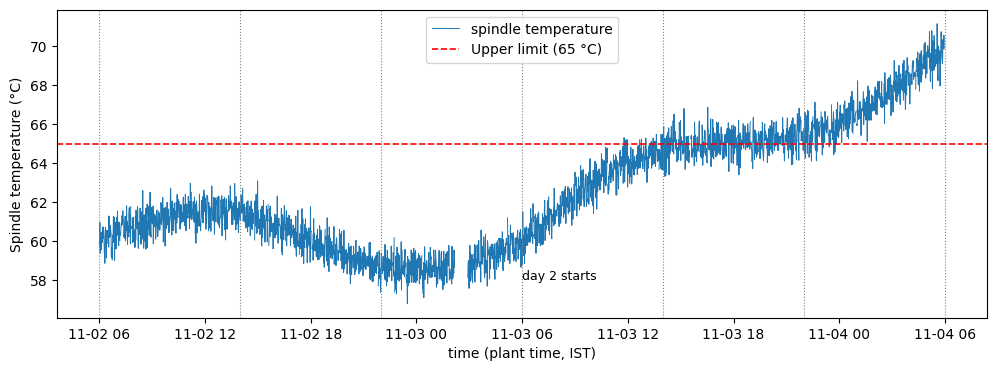

In [60]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(temp.index, temp["temp_clean"], lw=0.7, label="spindle temperature")
for d in pd.date_range("2026-11-02 06:00", "2026-11-04 06:00", freq="8h", tz="Asia/Kolkata"):
    ax.axvline(d, color="grey", ls=":", lw=0.8)                 # (v) operating context: shift changes
ax.annotate("day 2 starts", xy=(pd.Timestamp("2026-11-03 06:00", tz="Asia/Kolkata"), 58), fontsize=9)   # (iv)
ax.set_xlabel("time (plant time, IST)")                          # (i)
# TODO E3: (ii) add a y-axis label with the quantity AND its unit
#          (iii) draw the upper operating limit of 65 °C as a red dashed horizontal line (ax.axhline)
ax.set_ylabel("Spindle temperature (°C)")      # (ii) quantity + unit
ax.axhline(65, color="red", ls="--", lw=1.2, label="Upper limit (65 °C)")   # (iii)

ax.legend(); plt.show()

✍️ **Q E3.** Use the list of *things to investigate in a trend plot* (missing data, data drift, event occurrence, sensor errors, scale, patterns). What do you see in this plot?

*Your answer:* Answer:

Using the trend-plot checklist:

Missing data

There is a visible gap in the signal around the early hours of 3 Nov, indicating missing readings rather than a real drop in temperature. The gap is shown correctly because missing timestamps were reindexed and represented as NaN.

Data drift

The most important feature is a clear upward drift during the second production day.
On Day 1, the spindle temperature stays mostly between 58°C and 62°C.
After Day 2 starts, the temperature steadily rises and reaches 70-71°C by the end of the period.
This suggests a gradual process change rather than random variation.

Event occurrence

The annotation marks when Day 2 starts, and the sustained temperature increase begins after that point.
This supports the hypothesis that something changed in the process during Day 2, consistent with the simulated coolant problem.

Sensor errors

No obvious spikes to impossible values appear in the cleaned plot because the invalid readings (-40°C and 999.9°C) were removed.
The remaining signal looks physically realistic and continuous.

Scale

The y-axis scale is appropriate because it focuses on the operating range of the process (roughly 57-71°C) and makes the gradual increase easy to see.
A much wider scale would have hidden this important trend.

Patterns

There is a repeating daily up-and-down pattern, likely due to ambient or operating conditions.
Superimposed on this cycle is a strong long-term upward trend during Day 2.
The temperature crosses the 65°C operating limit around midday on 3 Nov and remains near or above it for extended periods.

Conclusion: The plot provides strong evidence that M03 experienced a gradual overheating problem on the second production day. The spindle temperature drifts upward, exceeds the 65°C limit for long periods, and this timing is consistent with the observed increase in scrap rate from 1.07% on 2 Nov to 5.97% on 3 Nov. This makes spindle temperature a plausible contributor to the higher scrap rate.

**E4. Relate temperature to scrap.** Bring both signals to the same time grain (one row per hour): the mean temperature of the hour and the scrap rate of M03's parts made in that hour.

In [61]:
m03h = m03.set_index("ts_local")
# TODO E4: hourly scrap rate of M03 = mean of (not is_good) per hour  ->  (~m03h["is_good"]).resample("h").mean()
#          hourly mean temperature: once from the RAW column temp_C, once from the CLEAN column temp_clean
m03h = m03.set_index("ts_local")

hourly = pd.DataFrame({
    "scrap_rate": (~m03h["is_good"]).resample("h").mean(),
    "temp_raw": temp["temp_C"].resample("h").mean(),
    "temp_clean": temp["temp_clean"].resample("h").mean()
}).dropna()

hourly.head()

,scrap_rate,temp_raw,temp_clean
2026-11-02 06:00:00+05:30,0.000000,60.175932,60.175932
2026-11-02 07:00:00+05:30,0.027397,57.280678,60.694035
2026-11-02 08:00:00+05:30,0.040000,60.879333,60.879333
2026-11-02 09:00:00+05:30,0.000000,61.063833,61.063833
2026-11-02 10:00:00+05:30,0.027027,61.404915,61.404915


In [62]:
# TODO E5: compute Pearson and Spearman correlation between scrap_rate and temp_raw, and between scrap_rate and temp_clean
# Hint: hourly["scrap_rate"].corr(hourly["temp_clean"], method="spearman")
corr = pd.DataFrame({
    "Pearson": [
        hourly["scrap_rate"].corr(hourly["temp_raw"], method="pearson"),
        hourly["scrap_rate"].corr(hourly["temp_clean"], method="pearson")
    ],
    "Spearman": [
        hourly["scrap_rate"].corr(hourly["temp_raw"], method="spearman"),
        hourly["scrap_rate"].corr(hourly["temp_clean"], method="spearman")
    ],
}, index=["raw temperature", "clean temperature"]).round(3)

corr

,Pearson,Spearman
raw temperature,0.423,0.659
clean temperature,0.818,0.788


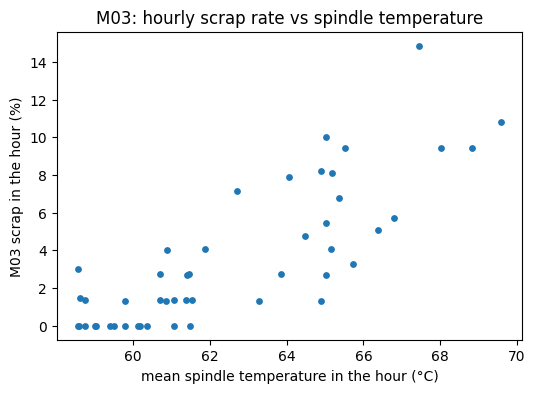

In [63]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(hourly["temp_clean"], 100 * hourly["scrap_rate"], s=15)
ax.set_xlabel("mean spindle temperature in the hour (°C)")
ax.set_ylabel("M03 scrap in the hour (%)")
ax.set_title("M03: hourly scrap rate vs spindle temperature")
plt.show()

✍️ **Q E5.** Why does the Pearson coefficient change so much between raw and clean temperature, while Spearman changes much less? What is your answer to the RQ, and what is your hypothesis about the physical cause?

*Your answer:* Pearson correlation is very sensitive to extreme values because it uses the actual numeric distances between observations. The sensor-error readings (-40°C and 999.9°C) distort the hourly averages in the raw temperature data, weakening the measured linear relationship between temperature and scrap. After cleaning the signal, the Pearson correlation increases substantially (from about 0.42 to 0.82), revealing a much stronger relationship.

Spearman correlation is based on the rank order of the observations rather than their exact values. The outliers therefore have much less influence on the ranking of hours from "coolest" to "hottest," so the Spearman coefficient changes only modestly (roughly 0.66 to 0.79).

For the research question (RQ), the evidence supports the claim that:

M03's scrap rate increased significantly on the second production day (about 1.07% to 5.97%).
Higher spindle temperature is strongly associated with higher scrap, especially after the temperature data is cleaned.
The scatter plot shows a clear positive trend: as hourly temperature rises, hourly scrap rate generally rises as well.

Hypothesis about the physical cause:

A likely cause is the cooling-system degradation/coolant problem indicated by the steadily rising spindle temperature on Day 2. As the spindle overheats:

Thermal expansion may affect machine geometry and dimensional accuracy.
Tool alignment or positioning accuracy may deteriorate.
Weld or press process parameters may drift out of specification.
Part dimensions may move closer to tolerance limits, increasing rejects.

Therefore, the most plausible hypothesis is that progressive overheating of M03 due to insufficient cooling caused process variation to increase, leading to the higher scrap rate observed on Day 2.

✍️ **Q E6.** Following the EDA loop, what would you do next to *test/validate* the hypothesis? Name two concrete checks.

*Your answer:* Compare scrap rates above and below the 65°C operating limit

Split M03 production into two groups:
Temperature ≤ 65°C
Temperature > 65°C
Calculate scrap rates for each group and perform a statistical test (e.g., chi-square test or two-proportion test).
If scrap is significantly higher above 65°C, this strengthens the overheating hypothesis.

Check whether scrap increases with temperature bands

Bin temperatures into ranges such as:
<60°C
60-62°C
62-64°C
64-66°C

66°C

Compute scrap rate in each band.
A consistent increase in scrap rate across temperature bands would provide evidence of a dose-response relationship rather than a coincidence.

Additional validation could include checking maintenance records or coolant flow data around the start of Day 2 to confirm that a cooling-system issue occurred at the same time as the temperature increase.

## Wrap-up
In this lab you went the whole way from raw exports to an answer: you **extracted** the data as text, **transformed** it (one ID spelling, one clock, numbers and sentinels, deduplication on the business key, master data with a validated join), **validated** it with rules, **loaded** it into a database, queried it with **SQL** (ratio of sums, LEFT JOIN, GROUP BY, no join fan-out), and finally used **EDA** — profiling, a six-element trend plot and correlation — to answer a real question. Lab 2 uses the same kind of thinking for OEE, SPC and machine learning.